In [1]:
import polars as pl
import numpy as np
import matplotlib.pyplot as plt
import sys

sys.path.append("..")
from src.cleaning.limpiado import limpiar_datos
from src.models.concentracion import gini_concentracion, curva_lorenz
from config.rutas import RUTA_DATOS_CRUDOS

df_limpio = limpiar_datos(RUTA_DATOS_CRUDOS)
print("Filas cargadas y limpias:", df_limpio.shape[0])

Filas cargadas y limpias: 24560


## Cálculo del Coeficiente de Gini por Entidad Federativa

Coeficiente de Gini ponderado por el factor de expansión.

In [3]:
casos_violencia = df_limpio.filter(pl.col("sufrio_violencia_pareja") == 1)

gini_entidades = gini_concentracion(
    df=casos_violencia,
    columna_grupo="nom_entidad",
    columna_valor="factor_expansion"#Este es lo que se utiliza para ponderar
)

print(f"Coeficiente de Gini territorial: {gini_entidades:.5f}")

Coeficiente de Gini territorial: 0.41525


## Construcción y Gráfica de la Curva de Lorenz

La Curva de Lorenz compara la proporción acumulada de entidades federativas (ordenadas de menor a mayor volumen de casos) contra la proporción acumulada de casos de violencia ponderados.

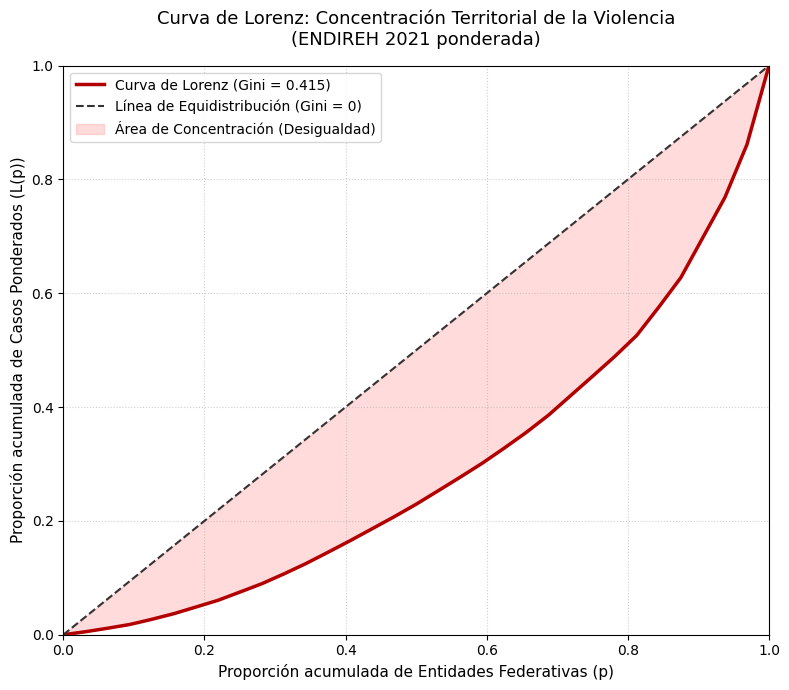

In [4]:
p, L = curva_lorenz(
    df=casos_violencia,
    columna_grupo="nom_entidad",
    columna_valor="factor_expansion"
)

plt.figure(figsize=(8, 7))
plt.plot(p, L, color="#b30000", lw=2.5, label=f"Curva de Lorenz (Gini = {gini_entidades:.3f})")
plt.plot([0, 1], [0, 1], color="#333333", linestyle="--", lw=1.5, label="Línea de Equidistribución (Gini = 0)")
plt.fill_between(p, p, L, color="#ff9999", alpha=0.35, label="Área de Concentración (Desigualdad)")

plt.title("Curva de Lorenz: Concentración Territorial de la Violencia\n(ENDIREH 2021 ponderada)", fontsize=13, pad=15)
plt.xlabel("Proporción acumulada de Entidades Federativas (p)", fontsize=11)
plt.ylabel("Proporción acumulada de Casos Ponderados (L(p))", fontsize=11)
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.grid(True, linestyle=":", alpha=0.6)
plt.legend(loc="upper left", fontsize=10)
plt.tight_layout()
plt.show()

## Interpretación de la Concentración Territorial

* **Curva de Lorenz y Coeficiente de Gini ($G \approx 0.415$):** 
  El coeficiente de 0.415 refleja una concentración territorial moderada (en una escala donde 0 es igualdad absoluta y 1 concentración total). Podemos observar que el 50% de los estados con menor incidencia apenas acumula el 20% de los casos del país, mientras que una pequeña fracción de entidades al final de la curva concentra más del 40% del total nacional. Esto demuestra que el volumen de mujeres afectadas no se reparte de manera homogénea en el territorio nacional.


## Tasa de prevalencia por entidad


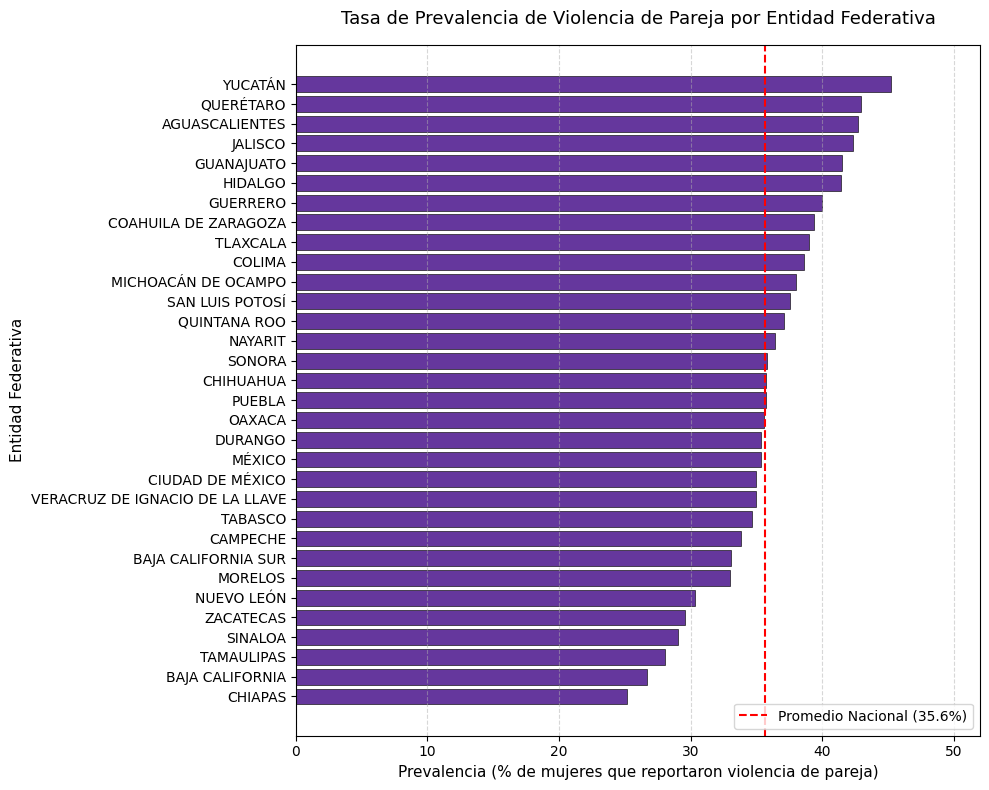

In [8]:
prevalencia_entidades = (
    df_limpio.group_by("nom_entidad")
    .agg([
        pl.col("factor_expansion").filter(pl.col("sufrio_violencia_pareja") == 1).sum().alias("casos_violencia"),
        pl.col("factor_expansion").sum().alias("total_mujeres")
    ])
    .with_columns(
        (pl.col("casos_violencia") / pl.col("total_mujeres") * 100).alias("prevalencia_pct")
    )
    .sort("prevalencia_pct", descending=True)
)


def arreglar_texto(texto):
    try:
        return texto.encode('latin1').decode('utf-8')
    except:
        return texto

entidades = [arreglar_texto(e) for e in prevalencia_entidades["nom_entidad"].to_list()]

prevalencias = prevalencia_entidades["prevalencia_pct"].to_list()

# Promedio ponderado nacional para comparar (es la linea roja)
tasa_nacional = (prevalencia_entidades["casos_violencia"].sum() / prevalencia_entidades["total_mujeres"].sum()) * 100

# barras horizontales
plt.figure(figsize=(10, 8))
plt.barh(entidades[::-1], prevalencias[::-1], color="#4a148c", alpha=0.85, edgecolor="black", linewidth=0.5)

plt.axvline(tasa_nacional, color="red", linestyle="--", lw=1.5, label=f"Promedio Nacional ({tasa_nacional:.1f}%)")

plt.title("Tasa de Prevalencia de Violencia de Pareja por Entidad Federativa", fontsize=13, pad=15)
plt.xlabel("Prevalencia (% de mujeres que reportaron violencia de pareja)", fontsize=11)
plt.ylabel("Entidad Federativa", fontsize=11)
plt.xlim(0, max(prevalencias) * 1.15)
plt.grid(axis="x", linestyle="--", alpha=0.5)
plt.legend(loc="lower right", fontsize=10)

plt.tight_layout()
plt.show()